In [11]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
import sys
sys.path.append("../../../")

import sys
print(sys.executable)

/Users/serenelobo/Library/Mobile Documents/com~apple~CloudDocs/Documents/University/comp9517-computer vision/cs9517/basilisk/.venv/bin/python


In [13]:
from src.utils.dataset import load_dataset
from src.methods.deep_learning.deep_learning import DeepLearningDetector
from src.evaluation.evaluator import Evaluator
from src.experiments.experiment_runner import (
    CleanExperiment,
    RandomSeverityExperiment,
    SeveritySweepExperiment,
    RandomCompositeExperiment
)

from src.evaluation.visualization import display_results
from src.experiments.transforms.corruptions import GaussianBlur

In [14]:

val_dataset = load_dataset("val")

detector = DeepLearningDetector()

detectors = {
    "deep_learning": detector
}

print(f"Loaded {len(val_dataset)} validation images")

Loaded 291 validation images


In [15]:
clean_results = CleanExperiment().run(val_dataset, detectors)

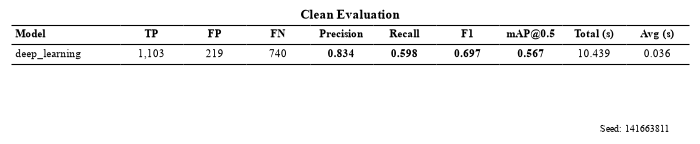

In [16]:
display_results(clean_results, seed=CleanExperiment().seed)

In [17]:
random_results = RandomSeverityExperiment(
    transform=GaussianBlur(),
    seed=42
).run(val_dataset, detectors)

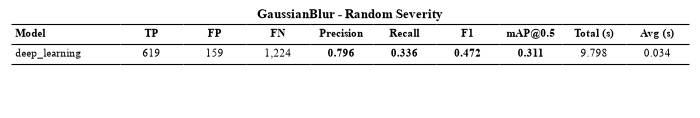

In [18]:
display_results(random_results)

In [19]:
severity_sweep = SeveritySweepExperiment(
    transform=GaussianBlur(),
    seed=42
).run(val_dataset, detectors)

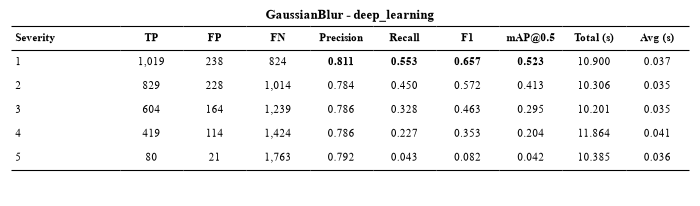

In [20]:
display_results(severity_sweep)